In [6]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [13]:
class bmi_state(TypedDict):
    weight_kg : float
    height_m : float
    bmi : float
    

In [14]:
def bmi_calculator(state : bmi_state) -> bmi_state:

    weight = state["weight_kg"]
    height = state["height_m"]

    bmi = weight/(height**2)

    state["bmi"] = round(bmi, 2)

    return state

In [15]:
#define graph
graph = StateGraph(bmi_state)

#add node
graph.add_node("bmi_state", bmi_calculator)

#add edges
graph.add_edge(START, "bmi_state")
graph.add_edge("bmi_state", END)

#complie
workflow = graph.compile()

In [16]:
initial_state = {"weight_kg" : 80, "height_m" : 1.73}
final_state = workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73}


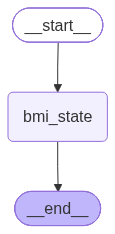

In [17]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())